# Corales de Panamá y eventos de El Niño: un análisis con datos abiertos
## Dataset de temperatura
### Limpieza de datos

#### Se limpian las series diarias de temperatura del mar de las 4 estaciones virtuales de Panamá de NOAA Coral Reef Watch. Los archivos originales se conservan sin modificar y el resultado se guarda en `datos/limpios/`
Por Edwin De Frías

In [1]:
import os
import re
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
with open("../datos/originales/panama_pacific_east.txt") as archivo:
    for numero, linea in enumerate(archivo):
        print(numero, linea, end="")
        if numero == 25:
            break

0 Name:
1 Panama Pacific East
2  
3 Polygon Middle Longitude:
4 -79.3250 
5  
6 Polygon Middle Latitude:
7 8.1750  
8  
9 Averaged Maximum Monthly Mean:
10 28.3059
11  
12 Averaged Monthly Mean (Jan-Dec):
13 26.6012 25.5309 25.1859 26.2011 27.8774 28.3059 28.2613 28.1484 27.9541 27.8285 27.8001 27.5621
14  
15 First Valid DHW Date:
16 1985 25 03
17  
18 First Valid BAA Date:
19 1985 31 03
20  
21 YYYY MM DD SST_MIN SST_MAX SST@90th_HS SSTA@90th_HS 90th_HS>0 DHW_from_90th_HS>1 BAA_7day_max
22 1985 01 01 26.6300 27.2800 26.6600     -0.1784       0.0000    0.0000            0
23 1985 01 02 26.5500 27.1600 26.5700     -0.2406       0.0000    0.0000            0
24 1985 01 03 26.4500 27.0000 26.4800     -0.3129       0.0000    0.0000            0
25 1985 01 04 26.3100 26.7700 26.3200     -0.4423       0.0000    0.0000            0


**Observación:** cada archivo tiene 21 líneas de información de la estación (nombre, coordenadas y promedios) antes de la tabla. El encabezado de la tabla está en la línea 21 y las columnas están separadas por espacios. El archivo también indica que el DHW es válido desde el 25 de marzo de 1985 y la alerta desde el 31 de marzo de 1985.

## 1. Cargamos los datos originales de NOAA
Fuente: NOAA Coral Reef Watch, 5 km Regional Virtual Stations v3.1. Son 4 archivos de texto, uno por estación virtual. Cada archivo tiene 21 líneas de información antes de la tabla, y las columnas están separadas por espacios.

In [3]:
estaciones = [
    "panama_atlantic_east",
    "panama_atlantic_west",
    "panama_pacific_east",
    "panama_pacific_west",
]

tablas = []

for estacion in estaciones:
    tabla = pd.read_csv(
        f"../datos/originales/{estacion}.txt",
        sep=r"\s+",
        skiprows=21,
    )
    tabla["estacion"] = estacion
    tablas.append(tabla)
    print(estacion, tabla.shape)

temperatura = pd.concat(tablas, ignore_index=True)
temperatura.shape

panama_atlantic_east (15284, 11)
panama_atlantic_west (15284, 11)
panama_pacific_east (15284, 11)
panama_pacific_west (15284, 11)


(61136, 11)

## 2. Antes de la limpieza

Revisamos cuántas filas y columnas tiene el dataset de temperatura, qué tipo de datos tiene cada columna, si hay valores faltantes y los valores mínimos y máximos, para tomar decisiones sobre la limpieza.

In [4]:
print("Filas y columnas:", temperatura.shape)
temperatura.info()

Filas y columnas: (61136, 11)
<class 'pandas.DataFrame'>
RangeIndex: 61136 entries, 0 to 61135
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   YYYY                61136 non-null  int64  
 1   MM                  61136 non-null  int64  
 2   DD                  61136 non-null  int64  
 3   SST_MIN             61136 non-null  float64
 4   SST_MAX             61136 non-null  float64
 5   SST@90th_HS         61136 non-null  float64
 6   SSTA@90th_HS        61136 non-null  float64
 7   90th_HS>0           61136 non-null  float64
 8   DHW_from_90th_HS>1  61136 non-null  float64
 9   BAA_7day_max        61136 non-null  int64  
 10  estacion            61136 non-null  str    
dtypes: float64(6), int64(4), str(1)
memory usage: 5.1 MB


Faltantes por columna:

In [5]:
faltantes_antes = temperatura.isna().sum()
print(faltantes_antes.to_string())

YYYY                  0
MM                    0
DD                    0
SST_MIN               0
SST_MAX               0
SST@90th_HS           0
SSTA@90th_HS          0
90th_HS>0             0
DHW_from_90th_HS>1    0
BAA_7day_max          0
estacion              0


Valores mínimos, máximos y promedios:

In [6]:
temperatura.describe().round(2)

,YYYY,MM,DD,SST_MIN,SST_MAX,SST@90th_HS,SSTA@90th_HS,90th_HS>0,DHW_from_90th_HS>1,BAA_7day_max
count,61136.00,61136.00,61136.00,61136.00,61136.00,61136.00,61136.00,61136.00,61136.00,61136.00
mean,2005.43,6.50,15.72,27.70,28.51,28.29,0.49,0.26,1.07,0.81
std,12.08,3.44,8.80,1.12,0.93,0.96,0.62,0.40,2.75,1.01
min,1985.00,1.00,1.00,19.61,24.11,23.74,-2.38,0.00,0.00,0.00
25%,1995.00,4.00,8.00,27.24,27.96,27.75,0.09,0.00,0.00,0.00
50%,2005.00,7.00,16.00,27.85,28.60,28.38,0.48,0.00,0.00,1.00
75%,2016.00,9.00,23.00,28.40,29.15,28.94,0.88,0.44,0.60,1.00
max,2026.00,12.00,31.00,30.36,31.22,31.19,3.46,2.66,21.29,7.00


Niveles de alerta en el dataset:

In [7]:
temperatura["BAA_7day_max"].value_counts().sort_index()

BAA_7day_max
0    26030
1    27391
2     4501
3     1306
4      867
5      522
6      495
7       24
Name: count, dtype: int64

**Niveles de alerta de blanqueamiento de NOAA (`BAA_7day_max`):**

| Nivel | Nombre en NOAA | Significado |
|---|---|---|
| 0 | No Stress | Sin estrés térmico |
| 1 | Bleaching Watch | Vigilancia: la temperatura empieza a subir |
| 2 | Bleaching Warning | Advertencia: el estrés se está acumulando |
| 3 | Alert Level 1 | Blanqueamiento probable (DHW ≥ 4) |
| 4 | Alert Level 2 | Blanqueamiento severo y mortalidad probable (DHW ≥ 8) |
| 5 | Alert Level 3 | Riesgo de mortalidad de varias especies (DHW ≥ 12) |
| 6 | Alert Level 4 | Riesgo de mortalidad severa (DHW ≥ 16) |
| 7 | Alert Level 5 | Riesgo de mortalidad casi total (DHW ≥ 20) |

NOAA amplió su escala con los niveles 5 a 7 para los casos de estrés térmico extremo.
En los datos aparecen todos los niveles, incluido el 7.

Revisamos las temperaturas mínimas y máximas por estación:

In [8]:
temperatura.groupby("estacion")[["SST_MIN", "SST_MAX", "DHW_from_90th_HS>1"]].agg(["min", "max"])

SST_MIN        SST_MAX        DHW_from_90th_HS>1         
                         min    max     min    max                min      max
estacion                                                                      
panama_atlantic_east   25.01  30.07   25.57  30.74                0.0  18.8957
panama_atlantic_west   25.22  30.36   25.45  31.22                0.0  21.2900
panama_pacific_east    19.61  29.93   24.11  30.97                0.0  18.7414
panama_pacific_west    25.06  30.34   26.38  31.20                0.0  18.3557

**Observaciones hasta ahora:**
- El dataset tiene 61,120 registros diarios (15,280 por estación, del 1 de enero de 1985 al la fecha de la ultima descarga de datos de temperatura) y 11 columnas.
- No hay valores vacíos en ninguna columna ni códigos de faltante como -999.
- Todas las columnas tienen el tipo correcto, pero la fecha está separada en tres columnas (`YYYY`, `MM`, `DD`) y hay que unirla.
- La temperatura mínima más baja (19.61 °C) es de Pacific East. No es un error: corresponde al afloramiento del Golfo de Panamá, que enfría el agua entre enero y abril.
- La anomalía promedio es +0.49 °C: el mar ha estado, en promedio, más caliente de lo normal.
- El DHW y la alerta valen 0 antes del 25 y el 31 de marzo de 1985, pero NOAA indica que antes de esas fechas no son válidos (el DHW necesita 12 semanas de datos para calcularse).

## 3. Revisión de columnas

A diferencia del dataset de corales, aquí no se elimina ninguna columna: las 10 columnas están completas (0 % de faltantes) y todas son necesarias para medir el estrés térmico de los corales.

| Columna original | Qué mide | ¿Se usa? |
|---|---|---|
| `YYYY`, `MM`, `DD` | Año, mes y día de la medición | Sí, para construir la fecha y unir con los corales por año |
| `SST_MIN`, `SST_MAX` | Temperatura superficial del mar mínima y máxima en la estación (°C) | Sí |
| `SST@90th_HS` | Temperatura en el punto más caliente de la estación (°C) | Sí |
| `SSTA@90th_HS` | Anomalía: cuánto más caliente o frío está el mar respecto a lo normal (°C) | Sí |
| `90th_HS>0` | HotSpot: cuánto supera la temperatura el máximo normal del mes más cálido (°C) | Sí |
| `DHW_from_90th_HS>1` | Degree Heating Weeks: estrés térmico acumulado en 12 semanas (°C-semanas) | Sí, es el indicador principal de blanqueamiento |
| `BAA_7day_max` | Nivel de alerta de blanqueamiento, el máximo de los últimos 7 días (0 a 7) | Sí |

## 4. Renombrar columnas a snake_case

Los nombres originales están en mayúsculas y tienen símbolos (`@`, `>`) que complican el código. Se renombran a snake_case (minúsculas y guion bajo) y en español. Se usa `anio`, igual que en el dataset de corales, porque es la columna con la que se unirán los dos datasets.

In [9]:
temperatura = temperatura.rename(columns={
    "YYYY": "anio",
    "MM": "mes",
    "DD": "dia",
    "SST_MIN": "sst_min",
    "SST_MAX": "sst_max",
    "SST@90th_HS": "sst_90",
    "SSTA@90th_HS": "anomalia",
    "90th_HS>0": "hotspot",
    "DHW_from_90th_HS>1": "dhw",
    "BAA_7day_max": "alerta",
})

temperatura.columns

Index(['anio', 'mes', 'dia', 'sst_min', 'sst_max', 'sst_90', 'anomalia',
       'hotspot', 'dhw', 'alerta', 'estacion'],
      dtype='str')

## 5. Tipos de datos correctos

- La fecha viene separada en tres columnas (`anio`, `mes`, `dia`); se unen en una sola columna `fecha` de tipo fecha.
- `anio` se convierte a `Int64`, el mismo tipo que usa el dataset de corales, para que la unión por año funcione sin problemas.

In [10]:
partes_fecha = temperatura[["anio", "mes", "dia"]].rename(columns={
    "anio": "year",
    "mes": "month",
    "dia": "day",
})

temperatura["fecha"] = pd.to_datetime(partes_fecha, errors="coerce")

temperatura[["anio", "mes", "dia", "fecha"]].head()

,anio,mes,dia,fecha
0,1985,1,1,1985-01-01
1,1985,1,2,1985-01-02
2,1985,1,3,1985-01-03
3,1985,1,4,1985-01-04
4,1985,1,5,1985-01-05


Revisamos cuántas fechas no se pudieron leer

In [11]:
print("Fechas que no se pudieron leer:", temperatura["fecha"].isna().sum())
print("Primera fecha:", temperatura["fecha"].min())
print("Última fecha:", temperatura["fecha"].max())
print("Tipo:", temperatura["fecha"].dtype)

Fechas que no se pudieron leer: 0
Primera fecha: 1985-01-01 00:00:00
Última fecha: 2026-11-05 00:00:00
Tipo: datetime64[us]


Revisamos que no falten días en la serie de cada estación

In [12]:
dias = temperatura.groupby("estacion")["fecha"].agg(["min", "max", "count"])
dias["dias_esperados"] = (dias["max"] - dias["min"]).dt.days + 1
dias["dias_faltantes"] = dias["dias_esperados"] - dias["count"]
dias

,min,max,count,dias_esperados,dias_faltantes
estacion,,,,,
panama_atlantic_east,1985-01-01,2026-11-05,15284,15284,0
panama_atlantic_west,1985-01-01,2026-11-05,15284,15284,0
panama_pacific_east,1985-01-01,2026-11-05,15284,15284,0
panama_pacific_west,1985-01-01,2026-11-05,15284,15284,0


Pasamos el año a entero, igual que en el dataset de corales

In [13]:
temperatura["anio"] = temperatura["anio"].astype("Int64")
temperatura["anio"].dtype

Int64Dtype()

## 6. Valores no válidos y faltantes

El dataset no tiene valores vacíos, pero no todos los valores son válidos. Según el encabezado de los archivos de NOAA, el DHW es válido desde el 25 de marzo de 1985 y la alerta desde el 31 de marzo de 1985, porque el DHW suma el calor de las 12 semanas anteriores y al inicio de la serie todavía no hay 12 semanas de datos. Antes de esas fechas, los archivos muestran 0, pero ese 0 significa "no calculado", no "sin estrés". Si se deja así, esos días contarían como días sin estrés térmico, y eso no es correcto.

In [14]:
inicio_dhw = pd.Timestamp("1985-03-25")
inicio_alerta = pd.Timestamp("1985-03-31")

antes_dhw = temperatura["fecha"] < inicio_dhw
antes_alerta = temperatura["fecha"] < inicio_alerta

print("Días con DHW no válido:", antes_dhw.sum())
print("Días con alerta no válida:", antes_alerta.sum())

Días con DHW no válido: 332
Días con alerta no válida: 356


Marcamos esos valores como vacíos

In [15]:
temperatura["alerta"] = temperatura["alerta"].astype("Int64")

temperatura.loc[antes_dhw, "dhw"] = None
temperatura.loc[antes_alerta, "alerta"] = None

temperatura[["fecha", "dhw", "alerta"]].iloc[80:92]

,fecha,dhw,alerta
80,1985-03-22,NaN,<NA>
81,1985-03-23,NaN,<NA>
82,1985-03-24,NaN,<NA>
83,1985-03-25,0.0,<NA>
84,1985-03-26,0.0,<NA>
85,1985-03-27,0.0,<NA>
86,1985-03-28,0.0,<NA>
87,1985-03-29,0.0,<NA>
88,1985-03-30,0.0,<NA>
89,1985-03-31,0.0,0


Revisamos que no haya valores imposibles

In [16]:
print("Mínima mayor que máxima:", (temperatura["sst_min"] > temperatura["sst_max"]).sum())
print("DHW negativo:", (temperatura["dhw"] < 0).sum())
print("HotSpot negativo:", (temperatura["hotspot"] < 0).sum())
print("Alerta fuera de 0 a 7:", ((temperatura["alerta"] < 0) | (temperatura["alerta"] > 7)).sum())

Mínima mayor que máxima: 0
DHW negativo: 0
HotSpot negativo: 0
Alerta fuera de 0 a 7: 0


Faltantes después de este paso

In [17]:
faltantes = temperatura.isna().sum()
porcentaje = (faltantes / len(temperatura) * 100).round(2)

tabla_faltantes = pd.DataFrame({"faltantes": faltantes, "porcentaje": porcentaje})
tabla_faltantes[tabla_faltantes["faltantes"] > 0]

,faltantes,porcentaje
dhw,332,0.54
alerta,356,0.58


### Decisión sobre los faltantes

| Columna | Faltantes | Decisión | Justificación |
|---|---|---|---|
| `dhw` | 332 (0.54 %) | Conservar como vacío, sin imputar | Son los días antes del 25/03/1985, cuando NOAA todavía no podía calcular el DHW. Rellenarlos con la media o la mediana inventaría estrés térmico que no se midió |
| `alerta` | 356 (0.58 %) | Conservar como vacío, sin imputar | Mismo motivo: antes del 31/03/1985 la alerta no es válida |

No se eliminan esas filas, porque las temperaturas de esos días sí son válidas y se usan en el análisis.

## 7. Tratamiento de atípicos

Se revisan dos tipos de valores extremos:
1. **Temperaturas muy bajas** en `sst_min` (hasta 19.61 °C).
2. **Anomalías muy altas o muy bajas** en `anomalia`, que podrían ser eventos de El Niño o La Niña.

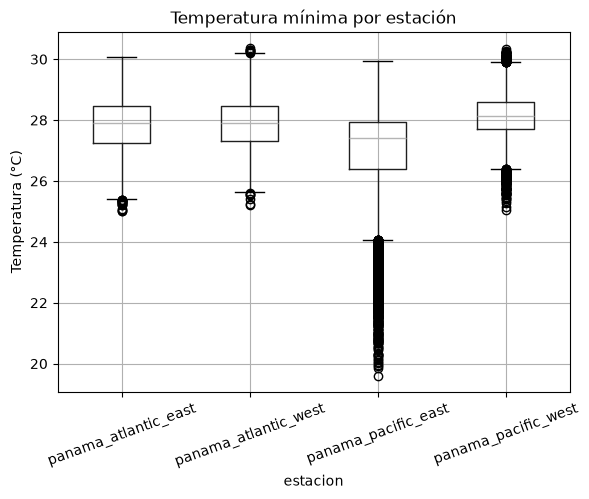

In [18]:
temperatura.boxplot(column="sst_min", by="estacion", rot=20)
plt.title("Temperatura mínima por estación")
plt.suptitle("")
plt.ylabel("Temperatura (°C)")
plt.show()

In [19]:
frias = temperatura[(temperatura["estacion"] == "panama_pacific_east") & (temperatura["sst_min"] < 24)]
frias["mes"].value_counts().sort_index()

mes
1     41
2    352
3    530
4     94
Name: count, dtype: int64

In [20]:
def es_atipico(valores):
    q1 = valores.quantile(0.25)
    q3 = valores.quantile(0.75)
    iqr = q3 - q1
    return (valores < q1 - 1.5 * iqr) | (valores > q3 + 1.5 * iqr)

temperatura["atipico_anomalia"] = temperatura.groupby("estacion")["anomalia"].transform(es_atipico)

temperatura["atipico_anomalia"].sum()

np.int64(887)

In [21]:
atipicos = temperatura[temperatura["atipico_anomalia"]]

print("Atípicos calientes por año:")
print(atipicos[atipicos["anomalia"] > 0]["anio"].value_counts().head(8))

print("\nAtípicos fríos por año:")
print(atipicos[atipicos["anomalia"] < 0]["anio"].value_counts().head(5))

Atípicos calientes por año:
anio
2026    134
2024    127
2023    104
2025     77
2010     35
1997     22
1998     17
2016     15
Name: count, dtype: Int64

Atípicos fríos por año:
anio
1985    38
2001    38
1999    36
1986    29
1989    21
Name: count, dtype: Int64


**Decisión:** los atípicos **no se eliminan**.
- Las temperaturas bajas de Pacific East (enero a abril) corresponden al afloramiento del Golfo de Panamá, un fenómeno natural de cada año en la estación seca.
- Las anomalías extremas coinciden con eventos de El Niño (1997-98, 2009-10, 2023-24) y de La Niña. Son justamente los eventos que el proyecto quiere estudiar; eliminarlos borraría la señal que buscamos.

Igual que con la profundidad en el dataset de corales, se marcan en una columna nueva, `atipico_anomalia` (True/False), para poder identificarlos en el análisis.

## 8. Clasificación por costa

Para unir la temperatura con los corales, cada estación se clasifica como "Caribe" o "Pacífico", con los mismos valores que en el dataset de corales. Las estaciones "atlantic" están en el Caribe y las "pacific" en el Pacífico.

In [22]:
costa_por_estacion = {
    "panama_atlantic_east": "Caribe",
    "panama_atlantic_west": "Caribe",
    "panama_pacific_east": "Pacífico",
    "panama_pacific_west": "Pacífico",
}

temperatura["costa"] = temperatura["estacion"].map(costa_por_estacion)

temperatura["costa"].value_counts()

costa
Caribe      30568
Pacífico    30568
Name: count, dtype: int64

Verificamos con las mismas reglas de coordenadas del dataset de corales

In [23]:
coordenadas = pd.DataFrame({
    "estacion": ["panama_atlantic_east", "panama_atlantic_west", "panama_pacific_east", "panama_pacific_west"],
    "longitud": [-78.700, -81.650, -79.325, -82.250],
    "latitud": [9.200, 9.200, 8.175, 7.725],
})

es_caribe = (
    ((coordenadas["longitud"] < -80.5) & (coordenadas["latitud"] > 8.7))
    | ((coordenadas["longitud"].between(-80.5, -78.5)) & (coordenadas["latitud"] > 9.1))
    | ((coordenadas["longitud"] > -78.5) & (coordenadas["latitud"] > 8.6))
)

coordenadas["costa_segun_reglas"] = "Pacífico"
coordenadas.loc[es_caribe, "costa_segun_reglas"] = "Caribe"
coordenadas

,estacion,longitud,latitud,costa_segun_reglas
0,panama_atlantic_east,-78.700,9.200,Caribe
1,panama_atlantic_west,-81.650,9.200,Caribe
2,panama_pacific_east,-79.325,8.175,Pacífico
3,panama_pacific_west,-82.250,7.725,Pacífico


## Años completos

La serie cambia cada vez que se realiza la descarga de los datos, así que el año 2026 está incompleto. Un promedio de 2026 no se puede comparar con el de un año completo (le faltan noviembre y diciembre), por eso se marca en una columna nueva.

In [24]:
dias_en_el_anio = temperatura.groupby(["estacion", "anio"])["fecha"].transform("count")
temperatura["anio_completo"] = dias_en_el_anio >= 365

temperatura.groupby("anio_completo")["anio"].unique()

anio_completo
False                                               [2026]
True     [1985, 1986, 1987, 1988, 1989, 1990, 1991, 199...
Name: anio, dtype: object

## 9. Duplicados

Se revisan dos tipos de duplicados:
1. Filas idénticas en todas las columnas.
2. Filas con la misma estación y la misma fecha: cada estación tiene una sola medición por día, así que una repetición sería un duplicado aunque los valores fueran distintos.

In [25]:
print("Filas idénticas:", temperatura.duplicated().sum())
print("Misma estación y fecha:", temperatura.duplicated(subset=["estacion", "fecha"]).sum())

Filas idénticas: 0
Misma estación y fecha: 0


No se encontraron duplicados: cada estación tiene exactamente una medición por día, sin repeticiones.

## 10. Perfil final (después de la limpieza)

Se compara el dataset antes y después de la limpieza: cantidad de filas, columnas y celdas vacías, y los tipos de datos finales.

In [26]:
temperatura_original = pd.concat(tablas, ignore_index=True)

temperatura_limpio = temperatura[[
    "fecha", "anio", "mes", "dia", "estacion", "costa",
    "sst_min", "sst_max", "sst_90", "anomalia", "hotspot", "dhw", "alerta",
    "atipico_anomalia", "anio_completo",
]].copy()

temperatura_limpio.shape

(61136, 15)

In [27]:
comparacion = pd.DataFrame({
    "Antes": [len(temperatura_original), temperatura_original.shape[1], temperatura_original.isna().sum().sum()],
    "Después": [len(temperatura_limpio), temperatura_limpio.shape[1], temperatura_limpio.isna().sum().sum()],
}, index=["Filas", "Columnas", "Celdas vacías"])

comparacion

,Antes,Después
Filas,61136,61136
Columnas,11,15
Celdas vacías,0,688


Tipos de datos finales

In [28]:
temperatura_limpio.info()

<class 'pandas.DataFrame'>
RangeIndex: 61136 entries, 0 to 61135
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   fecha             61136 non-null  datetime64[us]
 1   anio              61136 non-null  Int64         
 2   mes               61136 non-null  int64         
 3   dia               61136 non-null  int64         
 4   estacion          61136 non-null  str           
 5   costa             61136 non-null  str           
 6   sst_min           61136 non-null  float64       
 7   sst_max           61136 non-null  float64       
 8   sst_90            61136 non-null  float64       
 9   anomalia          61136 non-null  float64       
 10  hotspot           61136 non-null  float64       
 11  dhw               60804 non-null  float64       
 12  alerta            60780 non-null  Int64         
 13  atipico_anomalia  61136 non-null  bool          
 14  anio_completo     61136 non-null 

In [29]:
print("Valores de costa:", temperatura_limpio["costa"].unique())
print("Tipo de anio:", temperatura_limpio["anio"].dtype)

Valores de costa: <StringArray>
['Caribe', 'Pacífico']
Length: 2, dtype: str
Tipo de anio: Int64


## 11. Bitácora de limpieza

| Columna | Justificación |
|---|---|
| Todas | Se unieron los 4 archivos de NOAA (el dataset tiene un registro diario por estación desde el 1 de enero de 1985 hasta la fecha de la última descarga.). Se saltaron las 21 líneas de información de cada archivo y se agregó la columna `estacion` para identificar el origen de cada fila. |
| Todas | No se eliminó ninguna columna: las 10 están completas (0 % de faltantes) y todas sirven para medir el estrés térmico. |
| Todas | Nombres renombrados a snake_case y en español con un diccionario (`anio`, `mes`, `dia`, `sst_min`, `sst_max`, `sst_90`, `anomalia`, `hotspot`, `dhw`, `alerta`), quitando símbolos como `@` y `>`. Se usa `anio`, igual que en el dataset de corales. |
| `fecha` | Nueva: se construyó a partir de `anio`, `mes` y `dia`. Todas las fechas son válidas y no falta ningún día en la serie de las 4 estaciones. |
| `anio`, `alerta` | Convertidas a `Int64`, el entero que acepta vacíos; `anio` tiene así el mismo tipo que en el dataset de corales. |
| `dhw` | 332 valores (0.54 %) antes del 25/03/1985 pasados a vacío: NOAA indica que antes de esa fecha el DHW no es válido (necesita 12 semanas de datos). No se imputan para no inventar estrés térmico. |
| `alerta` | 356 valores (0.58 %) antes del 31/03/1985 pasados a vacío, por el mismo motivo. No se imputan. |
| Medidas | Se revisaron valores imposibles (mínima mayor que máxima, DHW o HotSpot negativos, alerta fuera de 0 a 7): no se encontró ninguno. |
| `sst_min` | Temperaturas bajas de Pacific East (hasta 19.61 °C) conservadas: ocurren solo de enero a abril y corresponden al afloramiento del Golfo de Panamá. |
| `atipico_anomalia` | Días marcados como atípicos por el método IQR (la cantidad exacta se muestra en la celda de la sección 7), calculado por estación. Se conservan porque coinciden con eventos de El Niño (1997-98, 2009-10, 2023-24) y La Niña. |
| `costa` | Nueva: "Caribe" o "Pacífico" según la estación, con los mismos valores del dataset de corales. Verificada con las mismas reglas de coordenadas. |
| `anio_completo` | Nueva: marca 2026 como año incompleto (se actualiza cada vez que se haga la descraga), para no compararlo con años completos. |
| Duplicados | Se revisaron filas idénticas y repeticiones de estación y fecha: no se encontró ninguna. |

## 12. Guardar los datos limpios

El resultado se guarda en `datos/limpios/temperatura_limpio.csv`. Los archivos originales no se modifican.

In [30]:
os.makedirs("../datos/limpios", exist_ok=True)
temperatura_limpio.to_csv("../datos/limpios/temperatura_limpio.csv", index=False)
print("Archivo guardado:", temperatura_limpio.shape)

Archivo guardado: (61136, 15)
